# 1

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [3]:
df=sns.load_dataset('diamonds')
df
#As colunas x, y e Z representam a largura, altura e profundidade do diamante, respectivamente.

#Seria impossível ter um diamante com largura, altura ou profundidade de 0, portanto, x y e z têm todos que ser maior que 0.
# Também o carat,preço, table e depth que devem ser maior que 0.

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


# 2

In [4]:
colunas_num=df.select_dtypes(include=['int','float','int64','float64']).columns
z_scores=np.abs((df[colunas_num]-df[colunas_num].mean())/df[colunas_num].std())
outliers_zscore=(z_scores>3).sum()
outliers_zscore

carat     439
depth     685
table     336
price    1206
x          43
y          34
z          55
dtype: int64

In [5]:
Q1 = df[colunas_num].quantile(0.25)
Q3 = df[colunas_num].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers_iqr = (
    (df[colunas_num] < limite_inferior) | (df[colunas_num] > limite_superior)
).sum()
outliers_iqr

carat    1889
depth    2545
table     605
price    3540
x          32
y          29
z          49
dtype: int64

In [6]:
comparacao_outliers = pd.DataFrame({
    'Z-score (> 3)': outliers_zscore,
    'IQR (1.5 * IQR)': outliers_iqr
})

print(comparacao_outliers)

       Z-score (> 3)  IQR (1.5 * IQR)
carat            439             1889
depth            685             2545
table            336              605
price           1206             3540
x                 43               32
y                 34               29
z                 55               49


# 3

<Axes: ylabel='carat'>

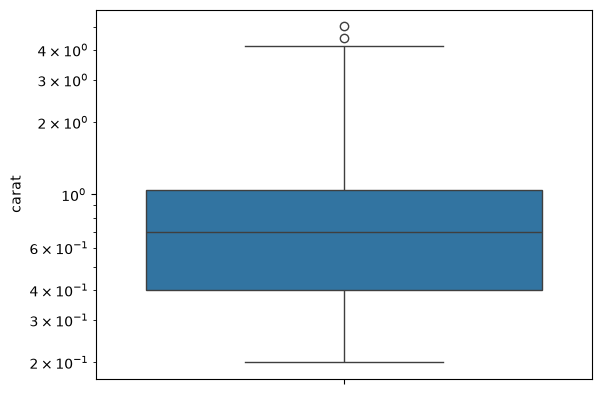

In [7]:
sns.boxplot(df['carat'],log_scale=True)

<Axes: xlabel='carat', ylabel='price'>

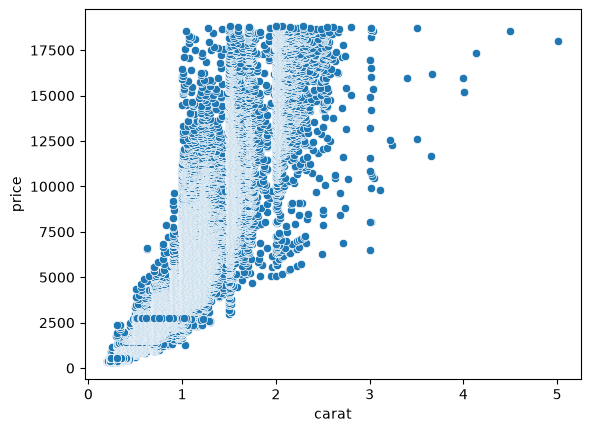

In [8]:
sns.scatterplot(data=df,x='carat',y='price')

# 4
- Os verdadeiros erros de registro encontrados foram, em primazia, dados negativos, e valores extremos seriam como o único diamante de quilate 5 acima.
- O critério utilizado foi principalmente sobre as regras de negócio de classificação de diamantes, pois diamantes grandes são raros, enquanto com valores negativos são impossíveis.


# 5


<Axes: xlabel='depth', ylabel='price'>

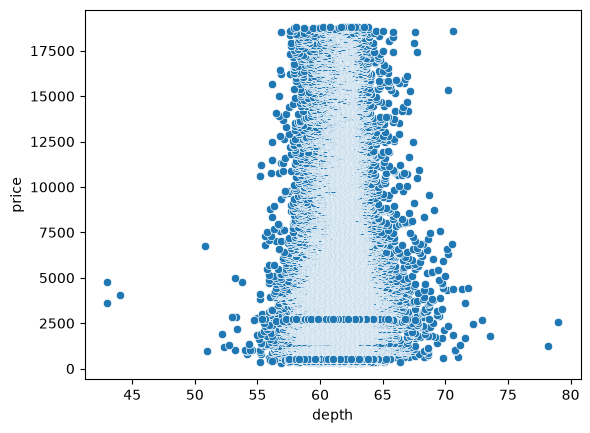

In [36]:
#Capping
sns.scatterplot(df,x='depth',y='price')

<Axes: xlabel='depth', ylabel='price'>

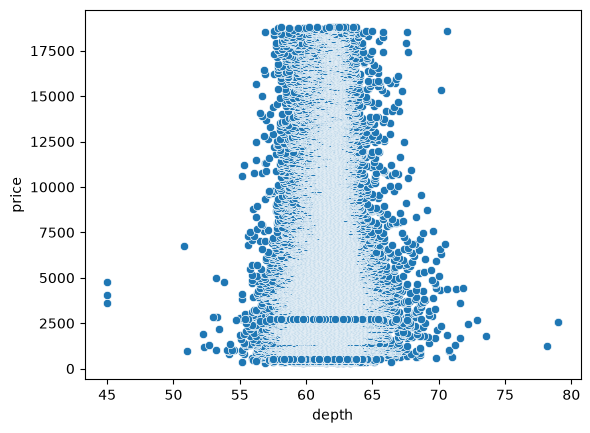

In [38]:
df_cap=df.copy()
df_cap['depth']=df['depth'].clip(lower=45,upper=80)
sns.scatterplot(data=df_cap,x='depth',y='price')
#Impacto: Extremos viram valores mínimos e máximos, podendo fazer com que dados sejam mais regularizados se forem dependentes dos mesmos.

<Axes: xlabel='x', ylabel='price'>

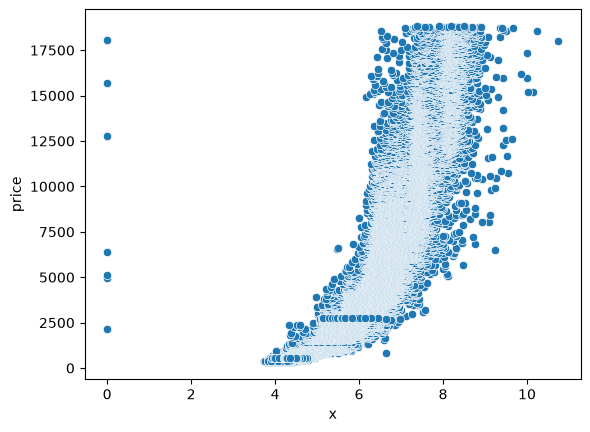

In [28]:
#Remoção
sns.scatterplot(df,x='x',y='price')

<Axes: xlabel='x', ylabel='price'>

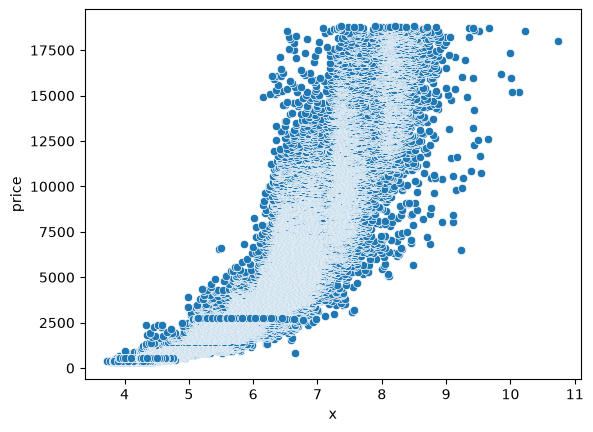

In [41]:
df_rem=df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
sns.scatterplot(data=df_rem,x='x',y='price')
#Dados são removidos se não são válidos, pode ser uma boa alternativa se não possuir muitos dados inválidos.

<Axes: xlabel='carat', ylabel='price'>

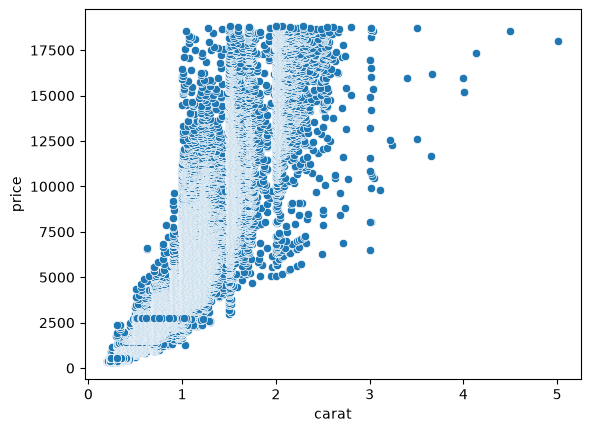

In [42]:
#Transformação
sns.scatterplot(data=df,x='carat',y='price')

<Axes: xlabel='carat', ylabel='price_log'>

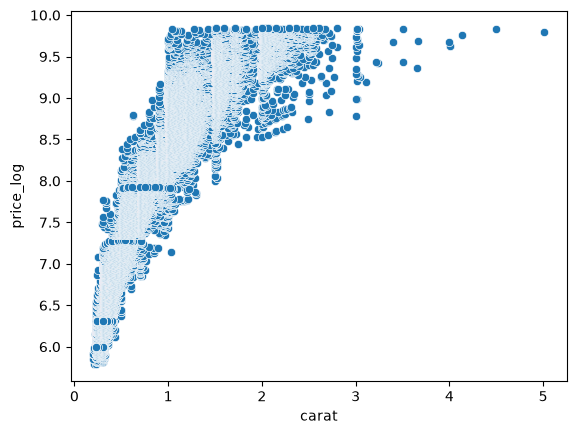

In [45]:

df_trans=df.copy()
df_trans['price_log']=np.log1p(df['price'])
sns.scatterplot(data=df_trans,x='carat',y='price_log')
#Ao invés do preço ser linear, ele é logarítmico, e retém 100% do dataset (usei log1p pois protege contra 0)

# Reflexão
- Que todos os dados são homogeneos,e nesse caso não vale, pois há muitos outliers.
- Um diamante de 4 quilates é um diamante raro, mas o objetivo da análise pode ser, por exemplo, analisar a mudança de preços em diamantes pequenos, que portanto, terá que remover diamantes grandes, como de quatro quilates.
- Tendências de diamantes baratos, qual tamanho, cor,claridade etc.

<Axes: xlabel='price', ylabel='Count'>

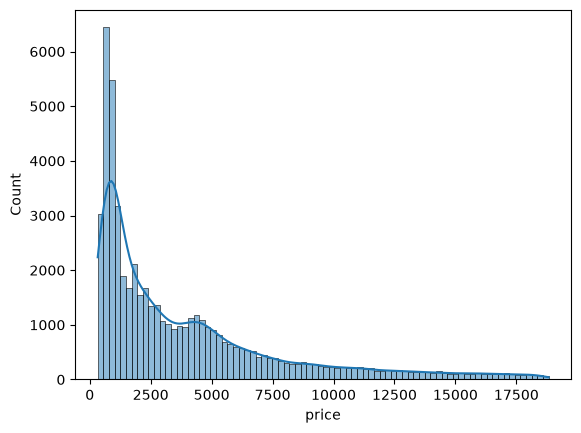

In [47]:
#Gráfico para a primeira
sns.histplot(data=df,x='price',kde=True)
# Pode-se ver que há muitos diamantes baratos e pouquíssimos caros.